In [1]:
# !pip3 show transformers
# !pip3 install --upgrade transformers

In [13]:
import os
import json
import random
from typing import List, Dict, Any, Tuple, Optional

import torch
import numpy as np
from PIL import Image, ImageDraw, ImageFont

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ipywidgets import HBox, VBox, Button, HTML, Output
from IPython.display import display, clear_output

from skimage.transform import resize

from transformers import (
    AutoProcessor,
    AutoModel,
    AutoImageProcessor,
    Sam2Model
)

from tqdm.notebook import tqdm
import glob

In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

SAM2_ID = "facebook/sam2-hiera-base-plus"
DINOV3_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
DATA_DIR = "data/dataset/"
ANNOTATIONS_DIR = "data/annotations/" 

In [ ]:
def load_feature_extraction_models() -> Dict[str, Any]:
    models = {}
    
    print(f"1/2: SAM2 ({SAM2_ID})...")
    models['sam_processor'] = AutoProcessor.from_pretrained(SAM2_ID)
    models['sam_model'] = Sam2Model.from_pretrained(SAM2_ID).to(DEVICE)
    models['sam_model'].eval()

    print(f"\n2/2: DINOv3 ({DINOV3_ID})...")
    models['dino_processor'] = AutoImageProcessor.from_pretrained(DINOV3_ID)
    models['dino_model'] = AutoModel.from_pretrained(DINOV3_ID).to(DEVICE)
    models['dino_model'].eval()
    
    return models

In [4]:
models = load_feature_extraction_models()

1/2: SAM2 (facebook/sam2-hiera-base-plus)...


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.



2/2: DINOv2 (facebook/dinov3-vits16-pretrain-lvd1689m)...


In [5]:
def segment_object_by_bbox(
    image: Image.Image,
    bbox: List[int],
    models: Dict
) -> Optional[np.ndarray]:
    sam_processor = models['sam_processor']
    sam_model = models['sam_model']
    
    input_boxes = [[bbox]]
    
    inputs = sam_processor(image, input_boxes=input_boxes, return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        outputs = sam_model(**inputs)

    best_mask_idx = torch.argmax(outputs.iou_scores).item()
    
    multi_masks = sam_processor.image_processor.post_process_masks(
        outputs.pred_masks,
        original_sizes=[image.size[::-1]],
        target_sizes=[image.size[::-1]]
    )[0]
    
    if multi_masks.shape[1] > best_mask_idx:
        best_mask = multi_masks[0, best_mask_idx].cpu().numpy()
        return best_mask
    else:
        return None

In [6]:
def extract_masked_object(
    image: Image.Image,
    bbox: List[int],
    mask: np.ndarray
) -> Image.Image:
    x1, y1, x2, y2 = [int(c) for c in bbox]
    
    crop = image.crop((x1, y1, x2, y2))
    crop_np = np.array(crop)
    
    cropped_mask_np = mask[y1:y2, x1:x2]
    
    crop_rgba = np.concatenate(
        [crop_np, np.full((crop_np.shape[0], crop_np.shape[1], 1), 255, dtype=np.uint8)],
        axis=-1
    )
    
    h, w, _ = crop_rgba.shape
    mask_h, mask_w = cropped_mask_np.shape
    
    if h != mask_h or w != mask_w:
        cropped_mask_np = resize(cropped_mask_np, (h, w), order=0, preserve_range=True, anti_aliasing=False).astype(bool)

    crop_rgba[~cropped_mask_np] = [0, 0, 0, 0]
    
    return Image.fromarray(crop_rgba)

In [7]:
def get_dinov3_embedding(
    object_image: Image.Image,
    models: Dict
) -> torch.Tensor:
    dino_processor = models['dino_processor']
    dino_model = models['dino_model']
    
    inputs = dino_processor(images=object_image.convert("RGB"), return_tensors="pt").to(DEVICE)
    
    with torch.no_grad():
        outputs = dino_model(**inputs)
    
    embedding = outputs.last_hidden_state[:, 0, :]
    
    return embedding.squeeze(0).cpu()

In [8]:
all_image_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.*")))
all_annotation_paths = sorted(glob.glob(os.path.join(ANNOTATIONS_DIR, "*.json")))

annotation_basenames = {os.path.splitext(os.path.basename(p))[0] for p in all_annotation_paths}

image_paths_synced = []
annotation_paths_synced = []

for img_path in tqdm(all_image_paths, desc="Проверка файлов"):
    img_basename = os.path.splitext(os.path.basename(img_path))[0]
    
    if img_basename in annotation_basenames:
        image_paths_synced.append(img_path)
        
        ann_path = os.path.join(ANNOTATIONS_DIR, f"{img_basename}.json")
        annotation_paths_synced.append(ann_path)

print(f"Images in {DATA_DIR}: {len(all_image_paths)}")
print(f"Annotations in {ANNOTATIONS_DIR}: {len(all_annotation_paths)}")
print(f"Pairs: {len(image_paths_synced)}")

Проверка файлов:   0%|          | 0/1804 [00:00<?, ?it/s]

Images in data/dataset/: 1804
Annotations in data/annotations/: 192
Pairs: 192


In [ ]:
samples = []
MAX_SAMPLES = None

for img_path, ann_path in tqdm(list(zip(image_paths_synced, annotation_paths_synced)),
                               desc="Process", total=len(image_paths_synced)):
    with open(ann_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    
    anns = data.get("annotations", [])
    if not isinstance(anns, list) or len(anns) == 0:
        continue

    image = Image.open(img_path).convert("RGB")
    
    for i, ann in enumerate(anns):
        bbox = ann.get('bbox')
        if not (isinstance(bbox, list) and len(bbox) == 4):
            continue

        object_mask = segment_object_by_bbox(image, bbox, models)
        if object_mask is None:
            continue

        masked_object_image = extract_masked_object(image, bbox, object_mask)
        samples.append({
            "img_path": img_path,
            "ann_path": ann_path,
            "ann_index": i,
            "bbox": bbox,
            "mask": object_mask,
            "masked": masked_object_image
        })

        if MAX_SAMPLES and len(samples) >= MAX_SAMPLES:
            break
    if MAX_SAMPLES and len(samples) >= MAX_SAMPLES:
        break

print(f"Masks: {len(samples)}")

In [ ]:
out = Output()
info = HTML()
btn_prev = Button(description="backward")
btn_next = Button(description="forward")
controls = HBox([btn_prev, btn_next])
ui = VBox([info, out, controls])

idx = {"i": 0}

def show(i):
    i = max(0, min(i, len(samples)-1))
    idx["i"] = i
    s = samples[i]

    mask = s["mask"]
    if isinstance(mask, Image.Image):
        mask = np.array(mask)
    if mask.dtype != np.uint8:
        m = mask.astype(np.float32)
        m = (255 * (m - m.min()) / (m.max() - m.min() + 1e-8)).astype(np.uint8)
        mask = m

    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(8, 5))
        img = Image.open(s["img_path"]).convert("RGB")
        axes[0].imshow(img)
        axes[0].imshow(mask, alpha=0.35)
        x1,y1,x2,y2 = s["bbox"]
        axes[0].add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1,
                                        fill=False, linewidth=2, color='cyan'))
        axes[0].set_title("Mask")
        axes[0].axis('off')

        axes[1].imshow(s["masked"])
        axes[1].set_title("Object")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

    base_img = os.path.basename(s["img_path"])
    base_ann = os.path.basename(s["ann_path"])
    info.value = f"<b>{i+1} / {len(samples)}</b> — image: <code>{base_img}</code>, ann: <code>{base_ann}</code>, idx: {s['ann_index']}"

def on_prev(_):
    show(idx["i"] - 1)
def on_next(_):
    show(idx["i"] + 1)

btn_prev.on_click(on_prev)
btn_next.on_click(on_next)

display(ui)
show(0)

### Data

In [133]:
import json
import math
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import StratifiedGroupKFold

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter

In [37]:
def parse_bbox(s):
    b = json.loads(s)
    return [int(round(float(x))) for x in b]

In [75]:
df = pd.read_csv(
    "data/dataset.csv",
    converters={"bbox": parse_bbox},
    encoding="utf-8"
)
df.head()

,base_name,model_name,class,bbox,species_label,disease_label,hollows,cracks,stem_damage,crown_damage,fruiting_bodies,dry_branches_frac
0,08yitoAmovM.json,gemini,a tree,"[10, 0, 284, 998]",Тополь белый,здоров,0.00,0.0,0.00,0.00,0.0,0.15
1,08yitoAmovM.json,gemini,a tree,"[75, 510, 185, 955]",Липа мелколистная,здоров,0.00,0.0,0.00,0.00,0.0,0.10
2,08yitoAmovM_obj1_a tree_0.449.json,gemini,a tree,"[0, 0, 280, 987]",Тополь черный,стволовая гниль,0.00,0.0,0.93,0.81,0.0,0.15
3,0He8bwiaCHM.json,gemini,a tree,"[155, 0, 1000, 1600]",Ива белая,здоров,0.93,0.0,0.81,0.00,0.0,0.05
4,0He8bwiaCHM.json,gemini,a tree,"[950, 250, 1200, 1050]",Клен ясенелистный,здоров,0.00,0.0,0.00,0.00,0.0,0.05


In [76]:
MIN_PER_CLASS = 2

counts = df["disease_label"].value_counts()
keep_diseases = counts[counts >= MIN_PER_CLASS].index

dropped_rows = len(df) - len(df[df["disease_label"].isin(keep_diseases)])
dropped_classes = counts[counts < MIN_PER_CLASS]

df = df[df["disease_label"].isin(keep_diseases)].reset_index(drop=True)
dropped_classes

disease_label
отсутствуют видимые признаки                           1
ядровая гниль, вызванная дереворазрушающими грибами    1
комлевая гниль                                         1
механическое повреждение                               1
березовый трутовик                                     1
повреждение насекомыми-филлофагами                     1
естественное отмирание ветвей                          1
фитофтороз                                             1
рак                                                    1
комплексное усыхание                                   1
корневая и комлевая гниль                              1
Name: count, dtype: int64

In [77]:
IMAGES_DIR = "data/dataset"
NUM_COLS = ["hollows","cracks","stem_damage","crown_damage","fruiting_bodies","dry_branches_frac"]

In [78]:
le_disease = LabelEncoder()
le_disease.fit(df["disease_label"].astype(str).values)

X_embed, X_num, keep_idx = [], [], []
y_species, y_disease = [], []

In [274]:
le_disease.classes_

array(['вертициллезное увядание', 'голландская болезнь вяза', 'здоров',
       'корневая губка', 'мучнистая роса', 'неизвестно', 'ржавчина',
       'стволовая гниль', 'халаровый некроз'], dtype=object)

In [79]:
for i, row in tqdm(df.iterrows(), total=len(df), desc="Extract embeddings"):
    stem = os.path.splitext(str(row["base_name"]))[0]
    img_path = os.path.join(IMAGES_DIR, stem + ".jpg")

    image = Image.open(img_path).convert("RGB")

    bbox = row["bbox"]

    object_mask = segment_object_by_bbox(image, bbox, models)
    if object_mask is None:
        continue
    
    masked_object_image = extract_masked_object(image, bbox, object_mask)
    emb = get_dinov3_embedding(masked_object_image, models)
    if emb is None:
        continue

    emb = np.asarray(emb).reshape(-1)

    nums = row[NUM_COLS].astype(float).values

    X_embed.append(emb)
    X_num.append(nums)
    keep_idx.append(i)
    y_disease.append(row["disease_label"])

Extract embeddings:   0%|          | 0/386 [00:00<?, ?it/s]

The channel dimension is ambiguous. Got image shape torch.Size([3, 385, 1]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
The channel dimension is ambiguous. Got image shape torch.Size([3, 225, 1]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
The channel dimension is ambiguous. Got image shape torch.Size([3, 452, 1]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.
The channel dimension 

In [ ]:
X_embed = np.vstack(X_embed).astype(np.float32)
X_num = np.vstack(X_num).astype(np.float32)
X = np.hstack([X_embed, X_num])

y_disease = le_disease.transform(np.array(y_disease))

In [81]:
assert X_embed.ndim == 2
N = X_embed.shape[0]

In [86]:
X_in = X_embed.astype(np.float32)
y_reg = df[NUM_COLS].to_numpy(np.float32)

In [87]:
y_disease = np.asarray(y_disease, dtype=np.int64)
assert len(y_disease) == N and len(y_reg) == N

In [169]:
strat_key = df["disease_label"].astype(str).values

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(sss.split(X_in, strat_key))

In [170]:
# groups = df['base_name'].astype(str).str.replace(r'\.json$', '', regex=True)

# sgkf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)
# train_idx, val_idx = next(sgkf.split(X_in, df['disease_label'].astype(str), groups))

In [171]:
def split(a): return a[train_idx], a[val_idx]

In [172]:
X_train, X_val = split(X_in)
yreg_train, yreg_val = split(y_reg)
yd_train,  yd_val   = split(y_disease)

print(f"Train: {len(train_idx)} | Val: {len(val_idx)}")
print("X dim:", X_in.shape[1], "| y_reg dim:", y_reg.shape[1])

Train: 308 | Val: 78
X dim: 384 | y_reg dim: 6


In [173]:
class EmbedDataset(Dataset):
    def __init__(self, X_in: np.ndarray, y_reg: np.ndarray, y_disease: np.ndarray):
        assert X_in.ndim == 2
        assert len(X_in) == len(y_reg) == len(y_disease)
        self.X_in = X_in.astype(np.float32, copy=False)
        self.y_reg = y_reg.astype(np.float32, copy=False)
        self.y_disease = y_disease.astype(np.int64, copy=False)

    def __len__(self):
        return self.X_in.shape[0]

    def __getitem__(self, idx):
        return {
            "x": torch.from_numpy(self.X_in[idx]),
            "y_reg": torch.from_numpy(self.y_reg[idx]),
            "y_disease": torch.tensor(self.y_disease[idx], dtype=torch.long),
        }

In [174]:
train_ds = EmbedDataset(X_train, yreg_train, yd_train)
val_ds = EmbedDataset(X_val, yreg_val, yd_val)

In [175]:
BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=False
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=False
)

In [176]:
def compute_class_weights(y: np.ndarray) -> torch.Tensor:
    counts = Counter(y.tolist())
    n = sum(counts.values())
    weights = np.zeros(max(counts.keys())+1, dtype=np.float32)
    for k, c in counts.items():
        weights[k] = n / (len(counts) * c)
    return torch.tensor(weights, dtype=torch.float32)

In [177]:
disease_weights = compute_class_weights(yd_train)
disease_weights

tensor([17.1111,  0.8347,  0.1967, 17.1111, 34.2222,  2.6325,  0.6844,  1.4879,
        17.1111])

In [178]:
print("train size:", len(train_ds), "| val size:", len(val_ds))
print("input dim:", X_train.shape[1], "| y_reg dim:", yreg_train.shape[1])
print("disease classes:", len(disease_weights))

train size: 308 | val size: 78
input dim: 384 | y_reg dim: 6
disease classes: 9


### Model

In [261]:
EMBEDDING_DIM = X_train.shape[1]
NUM_DISEASES  = len(le_disease.classes_)

HIDDEN_DIM = 256
DROPOUT_RATE = 0.4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
class Predictor(nn.Module):
    def __init__(
        self,
        embedding_dim: int,
        hidden_dim: int,
        dropout_rate: float,
        num_diseases: int
    ):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
        )

        self.reg_head = nn.Sequential(
            nn.Linear(hidden_dim, 6),
            nn.Sigmoid()
        )

        self.disease_head = nn.Linear(hidden_dim, num_diseases)

    def forward(self, x):
        feat = self.backbone(x)
        out = {
            "reg": self.reg_head(feat), # [B, 6] in [0,1]
            "disease_logits": self.disease_head(feat), # [B, NUM_DISEASES]
        }
        return out

In [262]:
model = Predictor(
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout_rate=DROPOUT_RATE,
    num_diseases=NUM_DISEASES,
).to(DEVICE)

In [253]:
dummy = torch.randn(4, EMBEDDING_DIM, device=DEVICE)
with torch.no_grad():
    pred = model(dummy)

print("Test")
print("Input:", dummy.shape)
for k, v in pred.items():
    print(f"{k}: {tuple(v.shape)}")

Test
Input: torch.Size([4, 384])
reg: (4, 6)
disease_logits: (4, 9)


### Train

In [216]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
import numpy as np

In [217]:
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=1.5, reduction='mean'):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weight, reduction='none')
        self.gamma = gamma
        self.reduction = reduction
    def forward(self, logits, target):
        ce = self.ce(logits, target)
        pt = torch.softmax(logits, dim=1).gather(1, target.view(-1,1)).squeeze(1).clamp(1e-6, 1-1e-6)
        fl = (1 - pt) ** self.gamma * ce
        if self.reduction == 'mean': return fl.mean()
        if self.reduction == 'sum':  return fl.sum()
        return fl

In [263]:
reg_crit = nn.SmoothL1Loss(reduction="mean")
# disease_crit = nn.CrossEntropyLoss(weight=disease_weights.to(DEVICE))
disease_crit = FocalLoss(weight=disease_weights.to(DEVICE), gamma=1.5)

In [264]:
LAMBDA_REG = 1.0
LAMBDA_DISEASE = 1.0
PATIENCE = 10

# AMP_ENABLED = torch.cuda.is_available()
# AMP_DEVICE  = "cuda" if AMP_ENABLED else "cpu"

In [265]:
optimizer = AdamW(model.parameters(), lr=3e-5, weight_decay=1e-3)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=5, min_lr=5e-6)
scaler = GradScaler(enabled=torch.cuda.is_available())

C:\Users\alex\AppData\Local\Temp\ipykernel_24952\493901883.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=torch.cuda.is_available())


In [266]:
def step_batch(batch, train: bool):
    model.train()
    x = batch["x"].to(DEVICE, non_blocking=True)
    y_r = batch["y_reg"].to(DEVICE, non_blocking=True)
    y_d = batch["y_disease"].to(DEVICE, non_blocking=True)

    with autocast(enabled=torch.cuda.is_available()):
        out = model(x)
        loss_reg = reg_crit(out["reg"], y_r)
        loss_disease = disease_crit(out["disease_logits"], y_d)
        loss = LAMBDA_REG*loss_reg + LAMBDA_DISEASE*loss_disease

    if train:
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

    with torch.no_grad():
        pred_disease = out["disease_logits"].argmax(dim=1)
        acc_disease  = (pred_disease == y_d).float().mean()
        mae_reg = (out["reg"] - y_r).abs().mean()

    return {
        "loss": float(loss.detach().cpu()),
        "loss_reg": float(loss_reg.detach().cpu()),
        "loss_disease": float(loss_disease.detach().cpu()),
        "acc_disease": float(acc_disease.cpu()),
        "mae_reg": float(mae_reg.cpu()),
    }

In [267]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    tot = {"loss":0,"loss_reg":0,"loss_disease":0,"acc_disease":0,"mae_reg":0,"n":0}
    for batch in loader:
        s = step_batch(batch, train=False)
        b = batch["x"].size(0)
        for k in tot:
            if k != "n": tot[k] += s[k]*b
        tot["n"] += b
    for k in list(tot.keys()):
        if k != "n": tot[k] = tot[k] / max(1, tot["n"])
    return tot

In [ ]:
def train_epochs(num_epochs=20, eval_every=1, verbose_every=1):
    best_val = np.inf
    best_state = None
    bad = 0
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[], "train_mae":[], "val_mae":[]}

    for epoch in range(1, num_epochs+1):
        model.train()
        ep = {"loss":0,"loss_reg":0,"loss_disease":0,"acc_disease":0,"mae_reg":0,"n":0}
        for batch in train_loader:
            s = step_batch(batch, train=True)
            b = batch["x"].size(0)
            for k in ep:
                if k!="n": ep[k] += s[k]*b
            ep["n"] += b
        for k in list(ep.keys()):
            if k!="n": ep[k] = ep[k] / max(1, ep["n"])
        
        val = evaluate(val_loader)
        scheduler.step(val["loss"])

        if epoch % eval_every == 0:
            val = evaluate(val_loader)

            hist["train_loss"].append(ep["loss"])
            hist["val_loss"].append(val["loss"])
            hist["train_acc"].append(ep["acc_disease"])
            hist["val_acc"].append(val["acc_disease"])
            hist["train_mae"].append(ep["mae_reg"])
            hist["val_mae"].append(val["mae_reg"])

            if epoch % verbose_every == 0:
                print(f"[{epoch:02d}] loss {ep['loss']:.4f}/{val['loss']:.4f} | "
                      f"acc {ep['acc_disease']:.3f}/{val['acc_disease']:.3f} | "
                      f"mae {ep['mae_reg']:.3f}/{val['mae_reg']:.3f}")

            if val["loss"] < best_val:
                best_val = val["loss"]
                best_state = {k:v.cpu() for k,v in model.state_dict().items()}
                torch.save(best_state, "best_model.pth")
            else:
                bad += 1
                if bad >= PATIENCE:
                    print(f"Early stop at epoch {epoch}, best val loss {best_val:.4f}")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    print(f"Best val loss: {best_val:.6f}")
    return hist

In [269]:
hist = train_epochs(num_epochs=200, eval_every=10, verbose_every=10)

C:\Users\alex\AppData\Local\Temp\ipykernel_24952\1067849607.py:7: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=torch.cuda.is_available()):


[10] loss 1.7265/1.9892 | acc 0.351/0.333 | mae 0.422/0.422
[20] loss 1.6306/2.0334 | acc 0.435/0.321 | mae 0.401/0.404
[30] loss 1.6254/2.0040 | acc 0.435/0.269 | mae 0.395/0.397
[40] loss 1.5424/2.0936 | acc 0.471/0.295 | mae 0.381/0.385
[50] loss 1.4979/2.1081 | acc 0.526/0.385 | mae 0.370/0.372
[60] loss 1.4650/2.0318 | acc 0.536/0.436 | mae 0.362/0.361
[70] loss 1.4154/1.8875 | acc 0.526/0.372 | mae 0.353/0.356
[80] loss 1.3902/2.0814 | acc 0.526/0.397 | mae 0.346/0.346
[90] loss 1.3563/2.0584 | acc 0.552/0.372 | mae 0.337/0.336
[100] loss 1.3119/2.0467 | acc 0.581/0.410 | mae 0.330/0.329
[110] loss 1.3252/2.0227 | acc 0.581/0.423 | mae 0.325/0.325
[120] loss 1.2874/1.9341 | acc 0.594/0.436 | mae 0.316/0.319
Early stop at epoch 120, best val loss 1.8875
Best val loss: 1.887510


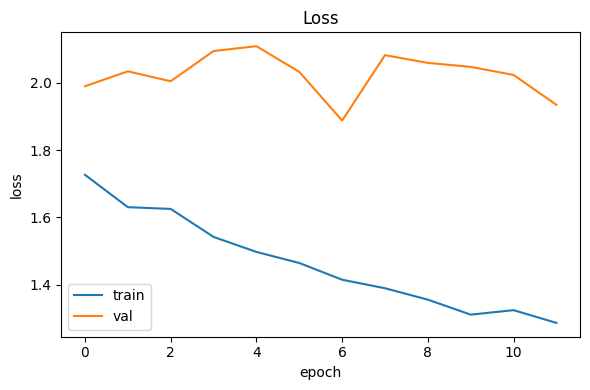

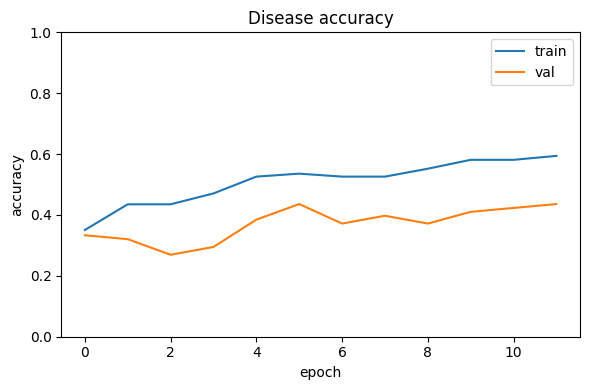

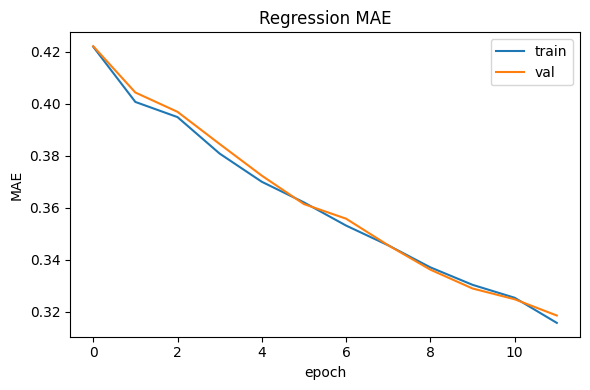

In [270]:
# loss
plt.figure(figsize=(6,4))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"],   label="val")
plt.title("Loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()

# Accuracy (disease)
plt.figure(figsize=(6,4))
plt.plot(hist["train_acc"], label="train")
plt.plot(hist["val_acc"],   label="val")
plt.title("Disease accuracy")
plt.ylim([0.0, 1.0])
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.tight_layout(); plt.show()

# MAE
plt.figure(figsize=(6,4))
plt.plot(hist["train_mae"], label="train")
plt.plot(hist["val_mae"],   label="val")
plt.title("Regression MAE")
plt.xlabel("epoch"); plt.ylabel("MAE"); plt.legend(); plt.tight_layout(); plt.show()


### Metrics

In [193]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, mean_absolute_error,
    mean_squared_error, r2_score
)

In [ ]:
@torch.no_grad()
def collect_preds(loader, model, device):
    model.eval()
    y_d_true, y_d_pred = [], []
    y_r_true, y_r_pred = [], []
    for batch in loader:
        x = batch["x"].to(device, non_blocking=True)
        out = model(x)
        # disease
        logits = out["disease_logits"].detach().cpu().numpy()
        preds = logits.argmax(axis=1)
        y_d_pred.append(preds)
        y_d_true.append(batch["y_disease"].cpu().numpy())
        # regression
        y_r_pred.append(out["reg"].detach().cpu().numpy())
        y_r_true.append(batch["y_reg"].cpu().numpy())
    y_d_true = np.concatenate(y_d_true)
    y_d_pred = np.concatenate(y_d_pred)
    y_r_true = np.concatenate(y_r_true)
    y_r_pred = np.concatenate(y_r_pred)
    return y_d_true, y_d_pred, y_r_true, y_r_pred

In [195]:
def classification_metrics_df(y_true, y_pred, class_names):
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro")
    f1_micro = f1_score(y_true, y_pred, average="micro")

    # per-class PRF
    prec, rec, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(len(class_names)), zero_division=0)
    cls_df = pd.DataFrame({
        "class": class_names,
        "support": support,
        "precision": prec,
        "recall": rec,
        "f1": f1,
    }).sort_values("support", ascending=False).reset_index(drop=True)

    # confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
    cm_df = pd.DataFrame(cm, index=[f"true:{c}" for c in class_names], columns=[f"pred:{c}" for c in class_names])

    # summary row
    summary = pd.DataFrame([{
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_micro": f1_micro,
        "n_samples": int(support.sum())
    }])

    return summary, cls_df, cm_df

In [196]:
def regression_metrics_df(y_true, y_pred, names=NUM_COLS):
    rows = []
    for j, name in enumerate(names):
        yt = y_true[:, j]
        yp = y_pred[:, j]
        mae = mean_absolute_error(yt, yp)
        mse = mean_squared_error(yt, yp)
        rmse = np.sqrt(mse)
        r2 = r2_score(yt, yp)
        rows.append({"target": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2})
    df = pd.DataFrame(rows)
    avg = pd.DataFrame([{
        "target": "<mean>",
        "MAE": df["MAE"].mean(),
        "MSE": df["MSE"].mean(),
        "RMSE": df["RMSE"].mean(),
        "R2": df["R2"].mean(),
    }])
    return df, avg

In [199]:
def evaluate_loader_pretty(loader, model, device, le_disease):
    y_d_true, y_d_pred, y_r_true, y_r_pred = collect_preds(loader, model, device)

    disease_classes = list(le_disease.classes_)
    cls_summary, cls_per_class, cm_df = classification_metrics_df(y_d_true, y_d_pred, disease_classes)

    reg_per_target, reg_avg = regression_metrics_df(y_r_true, y_r_pred, NUM_COLS)

    print("Disease classification (summary)")
    display(cls_summary)

    print("Disease classification: per-class")
    display(cls_per_class)

    # print("Confusion matrix")
    # display(cm_df)

    print("Regression per target")
    display(reg_per_target)

    print("Regression mean metrics")
    display(reg_avg)

    return {
        "y_d_true": y_d_true, "y_d_pred": y_d_pred,
        "y_r_true": y_r_true, "y_r_pred": y_r_pred,
        "cls_summary": cls_summary, "cls_per_class": cls_per_class, "cm_df": cm_df,
        "reg_per_target": reg_per_target, "reg_avg": reg_avg,
    }

In [200]:
val_results = evaluate_loader_pretty(val_loader, model, DEVICE, le_disease)

Disease classification (summary)


,accuracy,f1_macro,f1_micro,n_samples
0,0.5,0.296443,0.5,78


Disease classification: per-class


,class,support,precision,recall,f1
0,здоров,44,0.757576,0.568182,0.649351
1,ржавчина,13,0.400000,0.307692,0.347826
2,голландская болезнь вяза,10,0.260870,0.600000,0.363636
3,стволовая гниль,6,0.375000,0.500000,0.428571
4,неизвестно,4,0.333333,0.250000,0.285714
5,мучнистая роса,1,0.000000,0.000000,0.000000
6,вертициллезное увядание,0,0.000000,0.000000,0.000000
7,корневая губка,0,0.000000,0.000000,0.000000
8,халаровый некроз,0,0.000000,0.000000,0.000000


Regression per target


,target,MAE,MSE,RMSE,R2
0,hollows,0.293583,0.121213,0.348157,0.050944
1,cracks,0.257264,0.102665,0.320414,0.043092
2,stem_damage,0.322680,0.131888,0.363163,0.167653
3,crown_damage,0.231046,0.101739,0.318965,-0.010980
4,fruiting_bodies,0.063236,0.023598,0.153617,-0.034237
5,dry_branches_frac,0.122313,0.037585,0.193868,-0.036103


Regression mean metrics


,target,MAE,MSE,RMSE,R2
0,<mean>,0.21502,0.086448,0.283031,0.030062
